# C · Programa: asequibilidad, tamaño de mercado y costo

Del lado del programa (relevo por horas): contratación y precio por ingreso, dimensionamiento en la CDMX, subsidio y costo, y asequibilidad con ENASIC y ENIGH.

Este notebook junta varios análisis que antes estaban separados. Cada sección conserva su **número original** y escribe los mismos archivos en `resultados/`, con el mismo prefijo. Una cifra citada como "notebook 04" se rastrea a la sección 04.

| Sección | Tema | Archivo original | Escribe |
|---|---|---|---|
| [04](#s04) | Contratación por quintil, pago observado y asequibilidad | `04_enasic_precio_salarios_asequibilidad.ipynb` | `resultados/04_*` |
| [05](#s05) | Dimensionamiento del mercado domiciliario en la CDMX | `05_dimensionamiento_cdmx.ipynb` | `resultados/05_*` |
| [06](#s06) | Subsidio de un tercer pagador y costo del programa | `06_subsidio_y_costo_programa.ipynb` | `resultados/06_*` |
| [10](#s10) | Asequibilidad del relevo por horas (ENASIC) | `10_asequibilidad_relevo_horas.ipynb` | `resultados/10_*` |
| [14](#s14) | Asequibilidad del relevo por horas en la CDMX (ENIGH) | `14_enigh_asequibilidad_cdmx.ipynb` | `resultados/14_*` |

Requiere `Analysis/datos/enasic/` y `datos/enigh2022_coneval/`. La sección 14 lee `resultados/10_asequibilidad_relevo.csv`, que se genera antes en este mismo notebook.

Cada sección carga sus datos desde cero, así que no dependen de variables de secciones anteriores. Ejecutar con *Kernel → Restart & Run All* desde la carpeta `Analysis/`.

<a id="s04"></a>

---

*Sección 04 · antes `04_enasic_precio_salarios_asequibilidad.ipynb`*

# 04 · ENASIC 2022: contratación por quintil de ingreso, pago observado a cuidadoras y

```text
asequibilidad del cuidado domiciliario.

Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-09-22. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Qué responde
  A. ¿El precio es el cuello de botella? Tasa de contratación de enfermería/cuidadora por quintil de
     ingreso entre hogares con necesidad (discapacidad o 60+). Si en el quintil más alto sigue cerca de
     1-3 %, el precio no es la barrera principal (propuesto en la bitácora del 20-09).
  B. ¿Cuánto se paga hoy? Pago semanal, horas y pago por hora de cuidadoras, enfermería y trabajo
     doméstico de entrada por salida (muestra, sin ponderar y ponderado).
  C. ¿Quién puede pagar un salario digno? Proporción ponderada de hogares con necesidad cuyo ingreso
     permitiría pagar paquetes de 10, 20 y 40 h/semana a distintos salarios por hora.

Alcance: NACIONAL. La ENASIC no permite estimaciones para la CDMX ni por alcaldía. Nada de este script
se usa como dato territorial.

Datos: microdatos ENASIC 2022 en datos/enasic/ (no se suben al repositorio; ver .gitignore).
Salidas: resultados/04_*.csv
```

*Convertido de `04_enasic_precio_salarios_asequibilidad.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [1]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [2]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
hog = pd.read_csv(BASE / 'conjunto_de_datos_thogar_enasic_2022' / 'conjunto_de_datos' /
                  'conjunto_de_datos_thogar_ensasic_2022.csv', dtype=str)   # typo del INEGI en el nombre
hog.columns = [c.upper() for c in hog.columns]

In [3]:
# ---------- estimador (idéntico al notebook 03) ----------
Z90 = 1.6449
def estimar(df, y, x, peso, etiqueta=''):
    w = pd.to_numeric(df[peso]).to_numpy(float); y = np.asarray(y, float); x = np.asarray(x, float)
    X = (w * x).sum(); Y = (w * y).sum(); R = Y / X if X > 0 else np.nan
    z = w * (y - R * x) / X
    t = pd.DataFrame({'h': df.EST_DIS.values, 'u': df.UPM_DIS.values, 'z': z}).groupby(['h', 'u']).z.sum().reset_index()
    g = t.groupby('h').z; n_h = g.transform('size'); zbar = g.transform('mean')
    var = ((n_h / (n_h - 1)).where(n_h > 1, 0) * (t.z - zbar) ** 2).sum()
    se = np.sqrt(var); cv = se / R * 100 if R > 0 else np.nan
    prec = 'alta' if cv < 15 else ('moderada' if cv < 30 else 'baja')
    if not np.isfinite(cv): prec = 'no estimable (0 casos)'
    return dict(indicador=etiqueta, pct=R * 100, se=se * 100, cv=cv, li90=(R - Z90 * se) * 100,
                ls90=(R + Z90 * se) * 100, n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()),
                total_expandido=Y, precision=prec)
def es(col, val='1'): return (hog[col] == val).astype(int).to_numpy()
def num(s, invalidos): return pd.to_numeric(s.where(~s.isin(invalidos)), errors='coerce')
def wq(v, w, q):
    o = np.argsort(v); c = np.cumsum(w[o]) / w.sum(); return v[o][np.searchsorted(c, q)]

W = pd.to_numeric(hog.FAC_HOG).to_numpy(float)
necesidad = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')).astype(int).to_numpy()
contrata_cui = ((hog.P2_4_3 == '1') | (hog.P2_4_4 == '1')).astype(int).to_numpy()
contrata_dom = es('P2_4_1')

In [4]:
# ---------- ingreso: monto exacto (P3A.4) o punto medio del rango (P3A.5) ----------
MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}   # 11 = "más de $45,100": valor convencional
ing_exacto = num(hog.P3A_4, ('99999',))
ing_rango = hog.P3A_5.map(MID)
hog['ING'] = ing_exacto.fillna(ing_rango)
hog['ING_FUENTE'] = np.where(ing_exacto.notna(), 'monto', np.where(ing_rango.notna(), 'rango', 'sin dato'))

nec_ing = (necesidad == 1) & hog.ING.notna().to_numpy()
cortes = [wq(hog.ING.to_numpy()[nec_ing], W[nec_ing], q) for q in (.2, .4, .6, .8)]
hog['QUINTIL'] = np.where(hog.ING.isna(), np.nan, np.digitize(hog.ING, cortes, right=True) + 1)

In [5]:
# ---------- A. contratación por quintil ----------
filas = []
for q in range(1, 6):
    dq = (necesidad * (hog.QUINTIL == q).astype(int).to_numpy())
    filas.append(estimar(hog, contrata_cui * dq, dq, 'FAC_HOG', f'Q{q} | Contrata enfermería o cuidadora') | {'quintil': q, 'servicio': 'enfermería o cuidadora'})
    filas.append(estimar(hog, contrata_dom * dq, dq, 'FAC_HOG', f'Q{q} | Contrata trabajo doméstico entrada por salida') | {'quintil': q, 'servicio': 'doméstico entrada por salida'})
qa = pd.DataFrame(filas)
lim = [0] + cortes + [np.inf]
qa['ingreso_min'] = qa.quintil.map(lambda q: lim[q - 1]); qa['ingreso_max'] = qa.quintil.map(lambda q: lim[q])
cob = pd.Series(hog.ING_FUENTE[necesidad == 1]).value_counts().rename('hogares_con_necesidad_muestra')
qa.round(2).to_csv(OUT / '04_contratacion_por_quintil.csv', index=False, encoding='utf-8-sig')
cob.to_csv(OUT / '04_cobertura_ingreso.csv', encoding='utf-8-sig')

In [6]:
# ---------- B. pago observado ----------
SERV = {'3': 'Enfermería', '4': 'Cuidadora', '1': 'Doméstica entrada por salida'}
reg = []
for k, et in SERV.items():
    m = hog[f'P2_4_{k}'] == '1'
    pago = num(hog.loc[m, f'P2_8_{k}'], ('99999',))
    horas = num(hog.loc[m, f'P2_7_{k}'], ('98', '99')).replace(0, np.nan)
    d = pd.DataFrame({'servicio': et, 'pago_sem': pago, 'horas_sem': horas, 'w': W[m.to_numpy()],
                      'necesidad': necesidad[m.to_numpy()]})
    d['pago_hora'] = d.pago_sem / d.horas_sem
    reg.append(d)
reg = pd.concat(reg)
res = []
for (serv, grupo), d in [((s, 'todos los hogares'), g) for s, g in reg.groupby('servicio')] + \
                         [((s, 'hogares con necesidad'), g[g.necesidad == 1]) for s, g in reg.groupby('servicio')]:
    for var in ('pago_sem', 'horas_sem', 'pago_hora'):
        v = d[[var, 'w']].dropna()
        if len(v) == 0: continue
        res.append(dict(servicio=serv, grupo=grupo, variable=var, n=len(v),
                        p25=v[var].quantile(.25), mediana=v[var].median(), p75=v[var].quantile(.75),
                        mediana_ponderada=wq(v[var].to_numpy(), v.w.to_numpy(), .5)))
pb = pd.DataFrame(res)
# Actualización a pesos de 2026 con el INPC (base 2Q jul 2018 = 100).
# nov-2022 = 125.997 (mitad del levantamiento 24-oct a 16-dic-2022); ago-2026 = 145.462 (último publicado).
# Fuente: INEGI, INPC; valores consultados en elcontribuyente.mx/indicadores/inpc/ el 2026-09-22.
FACTOR_INPC = 145.462 / 125.997
pb['factor_inpc_2022_2026'] = round(FACTOR_INPC, 4)
for c in ('p25', 'mediana', 'p75', 'mediana_ponderada'):
    pb[c + '_pesos_2026'] = np.where(pb.variable == 'horas_sem', np.nan, pb[c] * FACTOR_INPC)
pb.round(2).to_csv(OUT / '04_pago_observado_cuidado.csv', index=False, encoding='utf-8-sig')

In [7]:
# ---------- C. asequibilidad ----------
# Salarios por hora (pesos de 2022, para comparar con ingresos de 2022):
#  - piso legal 2022: salario mínimo profesional 'Trabajador(a) del hogar' 187.92/día (resto del país) ÷ 8 h.
#    CONASAMI, Resolución DOF 08-dic-2021, vigente 01-ene-2022. CORREGIDO 2026-09-22: antes decía 187.22 (error de captura).
#  - mediana observada ENASIC de cuidadora o enfermería (este script)
#  - piso legal 2026: SM profesional 'Persona trabajadora del hogar' 342.47/día, zona general (ZLFN 440.87).
#    CONASAMI, DOF 09-dic-2025, vigente 01-ene-2026. Verificado 2026-09-22.
#  - tabulador CACEH 2026 cat. 8 (cuidado de personas mayores/con discapacidad) 904/día ÷ 8. NO es piso legal:
#    es referencia de sociedad civil (CACEH, abr-2026). Verificado 2026-09-22.
med_obs = reg[reg.servicio.isin(['Enfermería', 'Cuidadora'])].pago_hora.median()
SAL = {'Piso legal 2022 (SM prof. trabajadoras del hogar)': 187.92 / 8,
       'Mediana observada ENASIC 2022 (cuidadora/enfermería)': med_obs,
       'Piso legal 2026 en pesos de 2022': 342.47 / 8 / FACTOR_INPC,
       'Tabulador CACEH 2026 cat. 8 en pesos de 2022': 904 / 8 / FACTOR_INPC}
PAQ = {10: '10 h/sem (apoyo parcial)', 20: '20 h/sem (medio tiempo)', 40: '40 h/sem (jornada completa)'}
UMBRAL = (0.10, 0.20, 0.30)
m = nec_ing
ingreso = hog.ING.to_numpy()[m]; w = W[m]
ase = []
for s_et, s in SAL.items():
    for h, h_et in PAQ.items():
        costo = s * h * 4.33
        fila = dict(salario=s_et, salario_hora_2022=round(s, 2), paquete=h_et, costo_mensual_2022=round(costo),
                    costo_mensual_2026=round(costo * FACTOR_INPC), costo_pct_ingreso_mediano=round(costo / wq(ingreso, w, .5) * 100, 1))
        for u in UMBRAL:
            fila[f'pct_hogares_costo_<=_{int(u*100)}pct_ingreso'] = round(w[costo <= u * ingreso].sum() / w.sum() * 100, 1)
        ase.append(fila)
ase = pd.DataFrame(ase)
ase['n_muestra_hogares'] = int(m.sum())
ase.to_csv(OUT / '04_asequibilidad_paquetes.csv', index=False, encoding='utf-8-sig')

resumen = pd.DataFrame([
    dict(indicador='Hogares con necesidad (disc. o 60+), total expandido', valor=round(W[necesidad == 1].sum())),
    dict(indicador='Hogares con necesidad, muestra', valor=int(necesidad.sum())),
    dict(indicador='Ingreso mensual mediano ponderado (monto o rango), hogares con necesidad, $2022', valor=round(wq(ingreso, w, .5))),
    dict(indicador='Ingreso mensual p25 ponderado, hogares con necesidad, $2022', valor=round(wq(ingreso, w, .25))),
    dict(indicador='Ingreso mensual p75 ponderado, hogares con necesidad, $2022', valor=round(wq(ingreso, w, .75))),
    dict(indicador='Factor INPC nov-2022 -> ago-2026', valor=round(FACTOR_INPC, 4)),
])
resumen.to_csv(OUT / '04_resumen.csv', index=False, encoding='utf-8-sig')

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print(cob, '\n'); print(qa[['indicador', 'pct', 'cv', 'li90', 'ls90', 'n_muestra_dominio', 'n_muestra_si', 'precision', 'ingreso_min', 'ingreso_max']].round(1).to_string(), '\n')
print(pb.round(1).to_string(), '\n'); print(ase.to_string(), '\n'); print(resumen.to_string())

ING_FUENTE
monto       2054
sin dato     483
rango         17
Name: hogares_con_necesidad_muestra, dtype: int64 

                                            indicador   pct    cv  li90  ls90  n_muestra_dominio  n_muestra_si precision  ingreso_min  ingreso_max
0                Q1 | Contrata enfermería o cuidadora   1.0  52.8   0.1   1.8                443             4      baja          0.0       3200.0
1  Q1 | Contrata trabajo doméstico entrada por salida   3.2  39.1   1.1   5.3                443            13      baja          0.0       3200.0
2                Q2 | Contrata enfermería o cuidadora   0.4  70.8  -0.1   0.8                466             2      baja       3200.0       5000.0
3  Q2 | Contrata trabajo doméstico entrada por salida   3.1  40.4   1.1   5.2                466            16      baja       3200.0       5000.0
4                Q3 | Contrata enfermería o cuidadora   0.5  90.4  -0.2   1.3                406             2      baja       5000.0       8000.0
5  Q

## Gráficas
### A. ¿Contratan más los hogares con más ingreso?
Cuidado (enfermería o cuidadora) contra trabajo doméstico, por quintil. Barras rayadas: precisión baja.

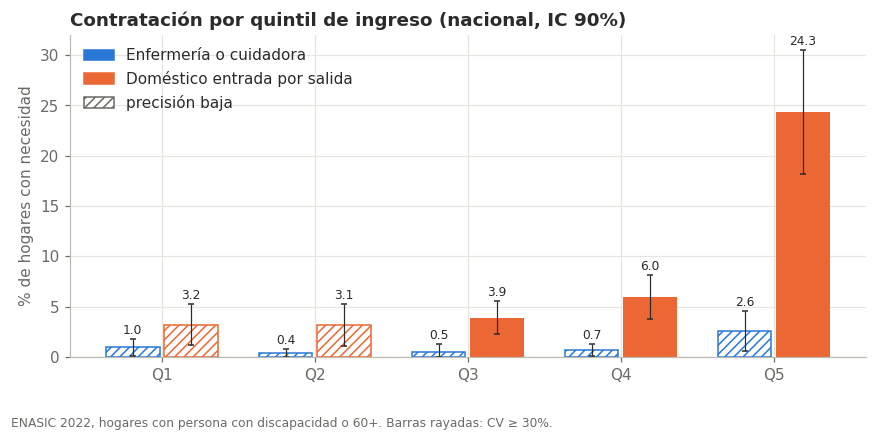

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, 6); w = .38
for i, (serv, col) in enumerate([('enfermería o cuidadora', AZUL), ('doméstico entrada por salida', NARANJA)]):
    d = qa[qa.servicio == serv].sort_values('quintil')
    b = ax.bar(x + (i - .5) * w, d.pct, w * .92, color=col, label=serv.capitalize(),
               yerr=[d.pct - d.li90.clip(lower=0), d.ls90 - d.pct], error_kw=dict(ecolor=TINTA, lw=.8, capsize=2))
    marcar_debiles(b, d.precision, col)
    for xi, (pc, hi) in zip(x + (i - .5) * w, zip(d.pct, d.ls90)):
        ax.text(xi, hi + .2, f'{pc:.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.set_xticks(x, [f'Q{q}' for q in x]); ax.set_ylabel('% de hogares con necesidad')
ax.legend(handles=[Patch(color=AZUL, label='Enfermería o cuidadora'), Patch(color=NARANJA, label='Doméstico entrada por salida'),
                   Patch(facecolor='white', edgecolor=TENUE, hatch='////', label='precisión baja')], loc='upper left')
ax.set_title('Contratación por quintil de ingreso (nacional, IC 90%)')
nota(fig, 'ENASIC 2022, hogares con persona con discapacidad o 60+. Barras rayadas: CV ≥ 30%.')
plt.show()

### B. ¿Cuánto se paga hoy por hora?
Percentiles 25–75 y mediana, sin ponderar, en pesos de 2026. Línea: piso legal 2026.

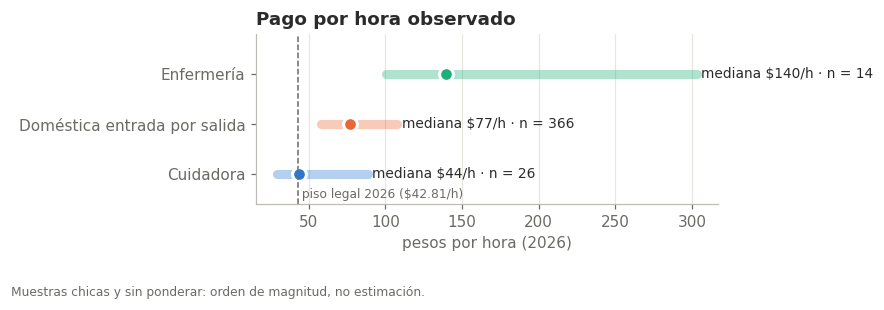

In [9]:
ph = pb[(pb.variable == 'pago_hora') & (pb.grupo == 'todos los hogares')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, r in ph.iterrows():
    ax.plot([r.p25_pesos_2026, r.p75_pesos_2026], [i, i], color=CAT[i], lw=6, alpha=.35, solid_capstyle='round')
    ax.plot(r.mediana_pesos_2026, i, 'o', color=CAT[i], ms=9, mec='white', mew=2)
    ax.text(r.p75_pesos_2026 + 3, i, f"mediana ${r.mediana_pesos_2026:,.0f}/h · n = {r.n}", va='center', fontsize=9)
ax.axvline(342.47 / 8, color=TENUE, ls='--', lw=1); ax.text(342.47 / 8, -.55, ' piso legal 2026 ($42.81/h)', color=TENUE, fontsize=8, va='bottom')
ax.set_yticks(range(len(ph)), ph.servicio); ax.set_xlabel('pesos por hora (2026)'); ax.grid(axis='y', visible=False)
ax.set_ylim(-.6, len(ph) - .2); ax.set_title('Pago por hora observado')
nota(fig, 'Muestras chicas y sin ponderar: orden de magnitud, no estimación.'); plt.show()

### C. ¿Quién podría pagar con su ingreso?
% de hogares con necesidad cuyo costo mensual queda en 20% de su ingreso o menos. Sin varianza de diseño.

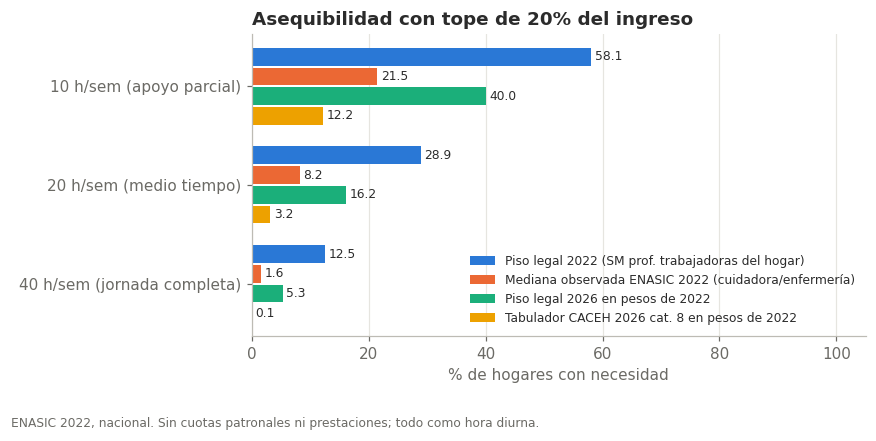

In [10]:
col = 'pct_hogares_costo_<=_20pct_ingreso'
sals = list(ase.salario.unique()); paqs = list(ase.paquete.unique())
fig, ax = plt.subplots(figsize=(8, 4)); h = .8 / len(sals)
for i, s in enumerate(sals):
    d = ase[ase.salario == s].set_index('paquete').loc[paqs]
    b = ax.barh(np.arange(len(paqs)) + i * h, d[col], h * .9, color=CAT[i], label=s)
    etiquetas(ax, b, d[col].values, horizontal=True, size=8)
ax.set_yticks(np.arange(len(paqs)) + h * (len(sals) - 1) / 2, paqs); ax.invert_yaxis(); ax.set_xlim(0, 105)
ax.set_xlabel('% de hogares con necesidad'); ax.legend(fontsize=8, loc='lower right'); ax.grid(axis='y', visible=False)
ax.set_title('Asequibilidad con tope de 20% del ingreso')
nota(fig, 'ENASIC 2022, nacional. Sin cuotas patronales ni prestaciones; todo como hora diurna.'); plt.show()

<a id="s05"></a>

---

*Sección 05 · antes `05_dimensionamiento_cdmx.ipynb`*

# 05 · Dimensionamiento del mercado de cuidado domiciliario para la CDMX.

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-09-22.  Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

ADVERTENCIA METODOLÓGICA — leer antes de citar cualquier cifra de este archivo.
La ENASIC 2022 es NACIONAL y no admite estimaciones para la CDMX (muestra de 7,021 viviendas,
sin representatividad estatal). Este script NO produce una estimación ENASIC para la CDMX.
Lo que hace es explícito y distinto: calcula TASAS nacionales con la ENASIC y las aplica a
CONTEOS de la CDMX del Censo 2020. El resultado es una INFERENCIA (nivel de evidencia:
probable), no una medición. Su sesgo conocido está declarado en la salida: la CDMX tiene una
estructura de edad más envejecida que el promedio nacional, así que la tasa nacional
SUBESTIMA la proporción de hogares con necesidad en la CDMX.

Salidas: resultados/05_*.csv
```

*Convertido de `05_dimensionamiento_cdmx.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [11]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [12]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
hog = pd.read_csv(BASE / 'conjunto_de_datos_thogar_enasic_2022' / 'conjunto_de_datos' /
                  'conjunto_de_datos_thogar_ensasic_2022.csv', dtype=str)
hog.columns = [c.upper() for c in hog.columns]
W = pd.to_numeric(hog.FAC_HOG).to_numpy(float)

nec  = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')).astype(int).to_numpy()
n60  = (hog.HN_C60MA == '1').astype(int).to_numpy()
cui  = ((hog.P2_4_3 == '1') | (hog.P2_4_4 == '1')).astype(int).to_numpy()
dom  = (hog.P2_4_1 == '1').astype(int).to_numpy()

tot_hog   = W.sum()
tasa_nec  = W[nec == 1].sum() / tot_hog
tasa_60   = W[n60 == 1].sum() / tot_hog
tasa_cui  = W[(nec == 1) & (cui == 1)].sum() / W[nec == 1].sum()
tasa_dom  = W[(nec == 1) & (dom == 1)].sum() / W[nec == 1].sum()

# --- Anclajes de la CDMX (Censo 2020, INEGI) ---
CDMX_VIV = 2_756_319   # viviendas particulares habitadas, CDMX. Comunicado INEGI Censo 2020 CdMx.
CDMX_POB = 9_209_944   # población total CDMX, Censo 2020.
CDMX_60  = 1_491_534   # 60+ implícita: % del CSV 'Población de más de 60 años' x población total.

tasas = pd.DataFrame([
 dict(concepto='Hogares del país (expandido, ENASIC)', valor=round(tot_hog), unidad='hogares', evidencia='confirmado (ENASIC)'),
 dict(concepto='Tasa nacional de hogares con persona con discapacidad o 60+', valor=round(tasa_nec*100,1), unidad='%', evidencia='confirmado (ENASIC)'),
 dict(concepto='Tasa nacional de hogares con persona 60+', valor=round(tasa_60*100,1), unidad='%', evidencia='confirmado (ENASIC)'),
 dict(concepto='Contratan enfermería o cuidadora, entre hogares con necesidad', valor=round(tasa_cui*100,1), unidad='%', evidencia='confirmado (ENASIC, CV moderado)'),
 dict(concepto='Contratan trabajo doméstico, entre hogares con necesidad', valor=round(tasa_dom*100,1), unidad='%', evidencia='confirmado (ENASIC, CV alto)'),
 dict(concepto='Viviendas particulares habitadas, CDMX', valor=CDMX_VIV, unidad='viviendas', evidencia='confirmado (Censo 2020)'),
 dict(concepto='Población total, CDMX', valor=CDMX_POB, unidad='personas', evidencia='confirmado (Censo 2020)'),
 dict(concepto='Población 60+, CDMX', valor=CDMX_60, unidad='personas', evidencia='probable (CSV sin productor ni año documentados)'),
])
tasas.to_csv(OUT / '05_tasas_y_anclajes.csv', index=False, encoding='utf-8-sig')

dim = pd.DataFrame([
 dict(nivel='Hogares CDMX con persona con discapacidad o 60+ (cota inferior)',
      valor=round(CDMX_VIV*tasa_nec), metodo='tasa nacional ENASIC x viviendas CDMX Censo 2020',
      evidencia='probable', sesgo='SUBESTIMA: la CDMX está más envejecida que el promedio nacional'),
 dict(nivel='Hogares CDMX que hoy contratan enfermería o cuidadora',
      valor=round(CDMX_VIV*tasa_nec*tasa_cui), metodo='lo anterior x tasa de contratación nacional',
      evidencia='probable', sesgo='doble inferencia; la CDMX tiene más ingreso que el promedio, podría SUBESTIMAR'),
 dict(nivel='Hogares CDMX con necesidad que hoy contratan trabajo doméstico',
      valor=round(CDMX_VIV*tasa_nec*tasa_dom), metodo='lo anterior x tasa nacional de trabajo doméstico',
      evidencia='probable', sesgo='es el mercado de servicio doméstico ya existente en esos hogares'),
])
dim.to_csv(OUT / '05_dimensionamiento_cdmx.csv', index=False, encoding='utf-8-sig')
print(tasas.to_string(), '\n'); print(dim.to_string())

                                                        concepto       valor     unidad                                         evidencia
0                           Hogares del país (expandido, ENASIC)  38785744.0    hogares                               confirmado (ENASIC)
1    Tasa nacional de hogares con persona con discapacidad o 60+        39.9          %                               confirmado (ENASIC)
2                       Tasa nacional de hogares con persona 60+        32.0          %                               confirmado (ENASIC)
3  Contratan enfermería o cuidadora, entre hogares con necesidad         1.0          %                  confirmado (ENASIC, CV moderado)
4       Contratan trabajo doméstico, entre hogares con necesidad         7.8          %                      confirmado (ENASIC, CV alto)
5                         Viviendas particulares habitadas, CDMX   2756319.0  viviendas                           confirmado (Censo 2020)
6                                 

## Gráfica
Tasas nacionales que el script aplica a los conteos de la CDMX. **Lo que se multiplica es nacional**: la escala de la CDMX es inferida.

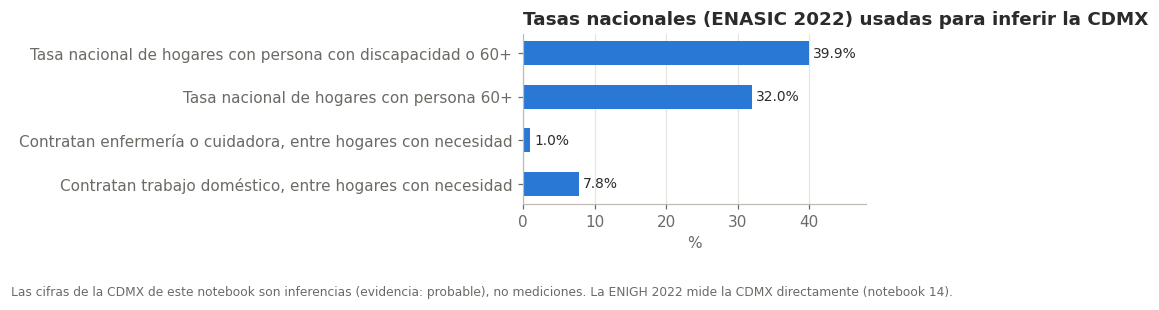

,nivel,valor,evidencia,sesgo
0,Hogares CDMX con persona con discapacidad o 60...,1099461,probable,SUBESTIMA: la CDMX está más envejecida que el ...
1,Hogares CDMX que hoy contratan enfermería o cu...,11300,probable,doble inferencia; la CDMX tiene más ingreso qu...
2,Hogares CDMX con necesidad que hoy contratan t...,86193,probable,es el mercado de servicio doméstico ya existen...


In [13]:
t = tasas[tasas.unidad == '%'].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 2.8))
b = ax.barh(t.concepto, t.valor, color=AZUL, height=.55)
etiquetas(ax, b, t.valor.values, horizontal=True, fmt='{:.1f}%')
ax.invert_yaxis(); ax.set_xlim(0, max(t.valor) * 1.2); ax.set_xlabel('%'); ax.grid(axis='y', visible=False)
ax.set_title('Tasas nacionales (ENASIC 2022) usadas para inferir la CDMX')
nota(fig, 'Las cifras de la CDMX de este notebook son inferencias (evidencia: probable), no mediciones. La ENIGH 2022 mide la CDMX directamente (notebook 14).')
plt.show()
dim[['nivel', 'valor', 'evidencia', 'sesgo']]

<a id="s06"></a>

---

*Sección 06 · antes `06_subsidio_y_costo_programa.ipynb`*

# 06 · ¿Cuánto tendría que aportar un tercer pagador para que el cuidado domiciliario

```text
sea asequible, y cuánto costaría eso en la CDMX?

Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-09-22.  Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Pregunta. El notebook 03 y el script 04 muestran que, a salario digno, casi ningún hogar con
necesidad puede pagar cuidado domiciliario con su propio ingreso. Este script cuantifica la
brecha: el subsidio mensual por hogar que haría que una proporción dada de hogares pudiera
pagar el resto sin rebasar el 20% de su ingreso, y el costo anual de ese subsidio si se
aplicara a los hogares de la CDMX.

Naturaleza de las cifras. La distribución de ingreso es NACIONAL (ENASIC 2022, ponderada).
El conteo de hogares de la CDMX es una INFERENCIA del script 05, no una medición. Por tanto
el costo anual es un ORDEN DE MAGNITUD para discutir viabilidad, no un presupuesto.

Salidas: resultados/06_*.csv
```

*Convertido de `06_subsidio_y_costo_programa.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [14]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [15]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados')
hog = pd.read_csv(BASE / 'conjunto_de_datos_thogar_enasic_2022' / 'conjunto_de_datos' /
                  'conjunto_de_datos_thogar_ensasic_2022.csv', dtype=str)
hog.columns = [c.upper() for c in hog.columns]
W = pd.to_numeric(hog.FAC_HOG).to_numpy(float)
nec = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')).to_numpy()

MID = {'1':1800,'2':4850.5,'3':7100.5,'4':9000.5,'5':11000.5,'6':13300.5,'7':16050.5,
       '8':19750.5,'9':25500.5,'10':37100.5,'11':55000}
ing = pd.to_numeric(hog.P3A_4.where(hog.P3A_4 != '99999'), errors='coerce').fillna(hog.P3A_5.map(MID))
m = nec & ing.notna().to_numpy()
INGRESO = ing.to_numpy()[m]; PESO = W[m]

FACTOR_INPC = 145.462 / 125.997        # nov-2022 -> ago-2026, INPC INEGI (base 2Q jul 2018)
INGRESO_2026 = INGRESO * FACTOR_INPC   # se indexa el ingreso a 2026 para comparar con salarios de 2026
UMBRAL = 0.20                          # el hogar no debe destinar más del 20% de su ingreso
CARGA_PATRONAL = 0.22                  # IMSS + Infonavit, aprox., para trabajo del hogar (POR CONFIRMAR
                                       # con la calculadora oficial del IMSS: adodigital.imss.gob.mx/pth_calculadora/)

SAL = {'Piso legal 2026 (SM prof. persona trabajadora del hogar, $342.47/día)': 342.47/8,
       'Tabulador CACEH 2026 cat. 8, cuidado de personas mayores ($904/día)': 904/8}
PAQ = {10:'10 h/sem', 20:'20 h/sem', 40:'40 h/sem'}
HOGARES_CDMX = 1_099_461               # cota inferior del script 05 (inferencia)

def cobertura(costo_neto):
    return PESO[costo_neto <= UMBRAL * INGRESO_2026].sum() / PESO.sum()

def subsidio_para(costo, objetivo):
    """Subsidio mensual por hogar que lleva la cobertura al objetivo. 0 si ya se alcanza."""
    if cobertura(costo) >= objetivo: return 0.0
    lo, hi = 0.0, costo
    for _ in range(60):
        mid = (lo + hi) / 2
        if cobertura(costo - mid) < objetivo: lo = mid
        else: hi = mid
    return hi

filas = []
for s_et, s in SAL.items():
    for h, h_et in PAQ.items():
        bruto = s * h * 4.33
        for carga, c_et in ((0.0, 'sin carga patronal'), (CARGA_PATRONAL, 'con IMSS e Infonavit (~22%)')):
            costo = bruto * (1 + carga)
            f = dict(salario=s_et, paquete=h_et, base=c_et,
                     costo_mensual_2026=round(costo),
                     pct_hogares_sin_subsidio=round(cobertura(costo)*100, 1))
            for obj in (0.25, 0.50):
                sub = subsidio_para(costo, obj)
                f[f'subsidio_para_{int(obj*100)}pct'] = round(sub)
                f[f'pct_del_costo_{int(obj*100)}pct'] = round(sub/costo*100, 1)
                f[f'costo_anual_cdmx_mdp_{int(obj*100)}pct'] = round(
                    sub * 12 * HOGARES_CDMX * obj / 1e6)
            filas.append(f)

d = pd.DataFrame(filas)
d.to_csv(OUT / '06_subsidio_por_paquete.csv', index=False, encoding='utf-8-sig')

notas = pd.DataFrame([
 dict(nota='Distribución de ingreso', detalle='ENASIC 2022 nacional, hogares con discapacidad o 60+, ponderada con FAC_HOG (n = %d)' % m.sum()),
 dict(nota='Indexación', detalle='Ingresos de 2022 llevados a pesos de 2026 con INPC (factor %.4f). Supone que el ingreso de estos hogares creció como el INPC: SUPUESTO, no dato.' % FACTOR_INPC),
 dict(nota='Umbral de asequibilidad', detalle='20%% del ingreso del hogar. Es una convención del equipo, no un estándar oficial.'),
 dict(nota='Carga patronal', detalle='%.0f%% sobre el salario, aproximada, para IMSS e Infonavit de persona trabajadora del hogar (obligatorio desde enero de 2023). POR CONFIRMAR con la calculadora oficial del IMSS.' % (CARGA_PATRONAL*100)),
 dict(nota='Hogares CDMX', detalle='%s, cota inferior inferida en el script 05. NO es una medición para la CDMX.' % f'{HOGARES_CDMX:,}'),
 dict(nota='Costo anual CDMX', detalle='subsidio x 12 x hogares x proporción cubierta. Orden de magnitud para discutir viabilidad, no presupuesto.'),
 dict(nota='Lo que NO dice', detalle='No dice que los hogares aceptarían el servicio si fuera asequible. El 35.9% declara que no contrataría a ningún precio (notebook 03).'),
])
notas.to_csv(OUT / '06_notas_metodologicas.csv', index=False, encoding='utf-8-sig')

In [16]:
# ───────── Escala nacional: el mismo subsidio aplicado a todo el país ─────────
# Se agrega el 2026-09-23, tras conocerse el Anexo Transversal 31 del PPEF 2026.
# El denominador nacional SÍ es una cifra de la propia ENASIC (hogares con necesidad,
# expandido), así que esta parte NO arrastra la inferencia territorial del script 05.
HOGARES_NAL = float(W[nec].sum())
ANEXO31_MDP = 466_675          # Anexo Transversal 31, PPEF 2026. Documento oficial de la
                               # Secretaría de las Mujeres. Consultado 2026-09-23.
SEMUJERES_MDP = 2_140          # Presupuesto 2026 de la Secretaría de las Mujeres, que coordina
                               # el SNPC. Fuente: Fundar. Consultado 2026-09-23. POR CONFIRMAR
                               # contra el PPEF.
CDMX_CUIDADOS_MDP = 6_747.7    # Solicitud CDMX 2026 para el Sistema Público de Cuidados.

nal = []
for s_et, sal in SAL.items():
    for h, h_et in PAQ.items():
        for carga, c_et in ((0.0, 'sin carga patronal'), (CARGA_PATRONAL, 'con IMSS e Infonavit (~22%)')):
            costo = sal * h * 4.33 * (1 + carga)
            for obj in (0.25, 0.50):
                sub_m = subsidio_para(costo, obj)
                anual = sub_m * 12 * HOGARES_NAL * obj / 1e6
                nal.append(dict(salario=s_et, paquete=h_et, base=c_et, cobertura=f'{int(obj*100)}%',
                                subsidio_mensual=round(sub_m), costo_anual_nacional_mdp=round(anual),
                                pct_anexo31=round(anual / ANEXO31_MDP * 100, 1),
                                veces_presupuesto_semujeres=round(anual / SEMUJERES_MDP, 1)))
nacional = pd.DataFrame(nal)
nacional.to_csv(OUT / '06_escala_nacional.csv', index=False, encoding='utf-8-sig')

anclas = pd.DataFrame([
 dict(ancla='Hogares con necesidad, nacional (ENASIC, expandido)', valor=round(HOGARES_NAL), evidencia='confirmado'),
 dict(ancla='Anexo Transversal 31, PPEF 2026 (mdp)', valor=ANEXO31_MDP, evidencia='confirmado · documento oficial SEMUJERES'),
 dict(ancla='Presupuesto 2026 Secretaria de las Mujeres (mdp)', valor=SEMUJERES_MDP, evidencia='probable · analisis de Fundar, por confirmar contra PPEF'),
 dict(ancla='Solicitud CDMX Sistema Publico de Cuidados 2026 (mdp)', valor=CDMX_CUIDADOS_MDP, evidencia='probable · prensa, por contrastar con decreto'),
])
anclas.to_csv(OUT / '06_anclas_presupuestales.csv', index=False, encoding='utf-8-sig')
print('\n--- escala nacional (piso legal) ---')
print(nacional[nacional.salario.str.startswith('Piso legal')].to_string())
print('\n', anclas.to_string())

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
print(d.to_string())


--- escala nacional (piso legal) ---
                                                                  salario   paquete                         base cobertura  subsidio_mensual  costo_anual_nacional_mdp  pct_anexo31  veces_presupuesto_semujeres
0   Piso legal 2026 (SM prof. persona trabajadora del hogar, $342.47/día)  10 h/sem           sin carga patronal       25%                 0                         0          0.0                          0.0
1   Piso legal 2026 (SM prof. persona trabajadora del hogar, $342.47/día)  10 h/sem           sin carga patronal       50%               284                     26318          5.6                         12.3
2   Piso legal 2026 (SM prof. persona trabajadora del hogar, $342.47/día)  10 h/sem  con IMSS e Infonavit (~22%)       25%                 0                         0          0.0                          0.0
3   Piso legal 2026 (SM prof. persona trabajadora del hogar, $342.47/día)  10 h/sem  con IMSS e Infonavit (~22%)       50%    

## Gráficas
### Costo anual del subsidio en la CDMX contra la solicitud de la CDMX
Piso legal 2026. Orden de magnitud: los hogares de la CDMX son la cota inferior inferida del notebook 05.

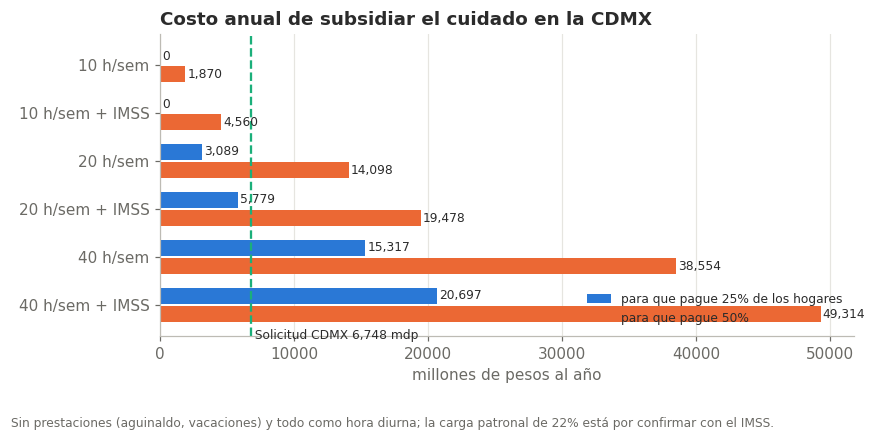

In [17]:
p = d[d.salario.str.startswith('Piso legal')].reset_index(drop=True)
lab = p.paquete + np.where(p.base.str.startswith('con'), ' + IMSS', '')
fig, ax = plt.subplots(figsize=(8, 4)); y = np.arange(len(p)); h = .38
for i, (c, et, colr) in enumerate([('costo_anual_cdmx_mdp_25pct', 'para que pague 25% de los hogares', AZUL), ('costo_anual_cdmx_mdp_50pct', 'para que pague 50%', NARANJA)]):
    b = ax.barh(y + i * h, p[c], h * .9, color=colr, label=et)
    etiquetas(ax, b, p[c].values, horizontal=True, fmt='{:,.0f}', dx=150, size=8)
ax.axvline(CDMX_CUIDADOS_MDP, color=AQUA, ls='--', lw=1.5); ax.text(CDMX_CUIDADOS_MDP, len(p) - .1, f' Solicitud CDMX {CDMX_CUIDADOS_MDP:,.0f} mdp', color=TINTA, fontsize=8)
ax.set_yticks(y + h / 2, lab); ax.invert_yaxis(); ax.set_xlabel('millones de pesos al año'); ax.grid(axis='y', visible=False)
ax.legend(fontsize=8, loc='lower right'); ax.set_title('Costo anual de subsidiar el cuidado en la CDMX')
nota(fig, 'Sin prestaciones (aguinaldo, vacaciones) y todo como hora diurna; la carga patronal de 22% está por confirmar con el IMSS.'); plt.show()

### Escala nacional contra el Anexo Transversal 31

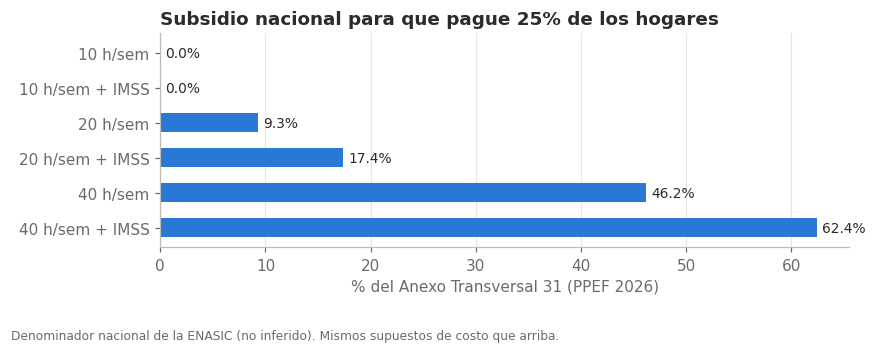

In [18]:
n = nacional[nacional.salario.str.startswith('Piso legal') & (nacional.cobertura == '25%')].reset_index(drop=True)
lab = n.paquete + np.where(n.base.str.startswith('con'), ' + IMSS', '')
fig, ax = plt.subplots(figsize=(8, 3.2))
b = ax.barh(lab, n.pct_anexo31, color=AZUL, height=.55)
etiquetas(ax, b, n.pct_anexo31.values, horizontal=True, fmt='{:.1f}%', dx=.5)
ax.invert_yaxis(); ax.set_xlabel('% del Anexo Transversal 31 (PPEF 2026)'); ax.grid(axis='y', visible=False)
ax.set_title('Subsidio nacional para que pague 25% de los hogares')
nota(fig, 'Denominador nacional de la ENASIC (no inferido). Mismos supuestos de costo que arriba.'); plt.show()

<a id="s10"></a>

---

*Sección 10 · antes `10_asequibilidad_relevo_horas.ipynb`*

# 10 · ENASIC 2022: asequibilidad del relevo por horas (programa opción C).

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-05. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Qué responde
  ¿Qué proporción de hogares con necesidad de cuidado (discapacidad o 60+) podría pagar un relevo
  acotado por horas, frente a la jornada completa?
  Extiende la parte C del script 04 con paquetes de relevo (3, 6, 9 y 12 h/semana). Usa exactamente la
  misma definición de hogar con necesidad, de ingreso (monto exacto P3A.4 o punto medio del rango P3A.5),
  de factor (FAC_HOG) y de salarios que el script 04, para que los resultados sean comparables.
  Primero reproduce los paquetes de 40 h del script 04 como control.

Limitaciones (leer antes de citar)
  - NACIONAL. No permite afirmaciones para la CDMX ni por alcaldía.
  - Proporción ponderada de hogares, sin varianza de diseño (igual que la parte C del script 04).
  - "Puede pagar" = costo mensual <= umbral del ingreso mensual del hogar (10, 20 o 30 %). Es un criterio
    convencional, no una medición de disposición a pagar. Que puedan pagar no implica que vayan a contratar
    (ver contratación por quintil del script 04).
  - Ingresos de 2022; salarios 2026 deflactados a pesos de 2022 con el INPC del script 04.
  - Sin cuotas patronales (IMSS, Infonavit).
  - El ingreso del rango más alto (más de $45,100) usa un valor convencional de $55,000 (script 04).

Datos: microdatos ENASIC 2022 en datos/enasic/ (no se suben al repositorio).
Salidas: resultados/10_asequibilidad_relevo.csv
```

*Convertido de `10_asequibilidad_relevo_horas.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [19]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [20]:
from pathlib import Path
import numpy as np, pandas as pd

BASE = Path('datos/enasic'); OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
hog = pd.read_csv(BASE / 'conjunto_de_datos_thogar_enasic_2022' / 'conjunto_de_datos' /
                  'conjunto_de_datos_thogar_ensasic_2022.csv', dtype=str)   # typo del INEGI en el nombre
hog.columns = [c.upper() for c in hog.columns]

def num(s, invalidos): return pd.to_numeric(s.where(~s.isin(invalidos)), errors='coerce')
def wq(v, w, q):
    o = np.argsort(v); c = np.cumsum(w[o]) / w.sum(); return v[o][np.searchsorted(c, q)]

W = pd.to_numeric(hog.FAC_HOG).to_numpy(float)
necesidad = ((hog.HN_CDISC == '1') | (hog.HN_C60MA == '1')).to_numpy()

MID = {'1': 1800, '2': 4850.5, '3': 7100.5, '4': 9000.5, '5': 11000.5, '6': 13300.5, '7': 16050.5,
       '8': 19750.5, '9': 25500.5, '10': 37100.5, '11': 55000}
ing = num(hog.P3A_4, ('99999',)).fillna(hog.P3A_5.map(MID)).to_numpy(float)

m = necesidad & ~np.isnan(ing)
ingreso = ing[m]; w = W[m]

# Mismos valores que el script 04 (ver sus fuentes y fechas de verificación).
FACTOR_INPC = 145.462 / 125.997
SAL = {'Piso legal 2026 (SM prof. personas trabajadoras del hogar)': 342.47 / 8 / FACTOR_INPC,
       'Tabulador CACEH 2026 cat. 8 (referencia, no piso legal)': 904 / 8 / FACTOR_INPC}
PAQ = {3: 'Relevo 3 h/sem', 6: 'Relevo 6 h/sem', 9: 'Relevo 9 h/sem', 12: 'Relevo 12 h/sem',
       40: 'Jornada completa 40 h/sem (control: script 04)'}
UMBRAL = (0.10, 0.20, 0.30)

filas = []
for s_et, s in SAL.items():
    for h, h_et in PAQ.items():
        costo = s * h * 4.33
        f = dict(salario=s_et, salario_hora_2026=round(s * FACTOR_INPC, 2), paquete=h_et, horas_semana=h,
                 costo_mensual_2026=round(costo * FACTOR_INPC), costo_mensual_2022=round(costo),
                 costo_pct_ingreso_mediano=round(costo / wq(ingreso, w, .5) * 100, 1))
        for u in UMBRAL:
            f[f'pct_hogares_costo_<=_{int(u*100)}pct_ingreso'] = round(w[costo <= u * ingreso].sum() / w.sum() * 100, 1)
        filas.append(f)
res = pd.DataFrame(filas)
res['n_muestra_hogares'] = int(m.sum())
res['alcance'] = 'nacional; proporción ponderada (FAC_HOG) sin varianza de diseño'
res.to_csv(OUT / '10_asequibilidad_relevo.csv', index=False, encoding='utf-8-sig')

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print(res.drop(columns=['alcance']).to_string())

                                                      salario  salario_hora_2026                                         paquete  horas_semana  costo_mensual_2026  costo_mensual_2022  costo_pct_ingreso_mediano  pct_hogares_costo_<=_10pct_ingreso  pct_hogares_costo_<=_20pct_ingreso  pct_hogares_costo_<=_30pct_ingreso  n_muestra_hogares
0  Piso legal 2026 (SM prof. personas trabajadoras del hogar)              42.81                                  Relevo 3 h/sem             3                 556                 482                        7.1                                66.2                                87.2                                95.3               2071
1  Piso legal 2026 (SM prof. personas trabajadoras del hogar)              42.81                                  Relevo 6 h/sem             6                1112                 963                       14.2                                35.5                                66.2                                79.7         

## Gráfica
% de hogares con necesidad que podrían pagar cada paquete, según el tope del ingreso. Sin varianza de diseño; nacional.

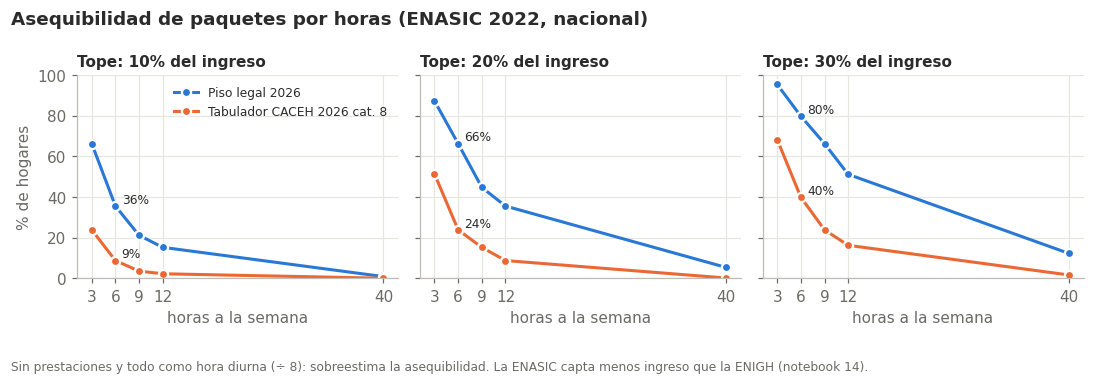

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, u in zip(axs, (10, 20, 30)):
    col = f'pct_hogares_costo_<=_{u}pct_ingreso'
    for i, s in enumerate(SAL):
        d = res[res.salario == s].sort_values('horas_semana')
        ax.plot(d.horas_semana, d[col], '-o', color=CAT[i], lw=2, ms=6, mec='white', mew=1.5, label=s.split(' (')[0])
        ax.text(d.horas_semana.iloc[1] + .8, d[col].iloc[1], f'{d[col].iloc[1]:.0f}%', fontsize=8, va='bottom')
    ax.set_title(f'Tope: {u}% del ingreso', fontsize=10); ax.set_xticks([3, 6, 9, 12, 40]); ax.set_xlabel('horas a la semana')
axs[0].set_ylabel('% de hogares'); axs[0].legend(fontsize=8, loc='upper right'); axs[0].set_ylim(0, 100)
fig.suptitle('Asequibilidad de paquetes por horas (ENASIC 2022, nacional)', x=.01, ha='left', fontweight='bold')
nota(fig, 'Sin prestaciones y todo como hora diurna (÷ 8): sobreestima la asequibilidad. La ENASIC capta menos ingreso que la ENIGH (notebook 14).')
plt.show()

<a id="s14"></a>

---

*Sección 14 · antes `14_enigh_asequibilidad_cdmx.ipynb`*

# 14 · ENIGH 2022 (base de pobreza CONEVAL): asequibilidad del relevo por horas en la CDMX.

```text
Proyecto integrador 7.º semestre LCDN · Observatorio de Datos para la Economía del Cuidado
Creado: 2026-10-06. Ejecutar con Kernel → Restart & Run All desde la carpeta Analysis/

Qué responde
  1. ¿Qué proporción de hogares de la CDMX con necesidad de cuidado (alguien de 60+ o con discapacidad)
     podría pagar los paquetes de relevo del script 10, con su ingreso propio?
  2. ¿Cambia la conclusión del script 10 (ENASIC, nacional) si el ingreso se mide con la ENIGH?
     La ENIGH mide el ingreso con un módulo detallado; la ENASIC con una sola pregunta (monto o rango).

Por qué la ENIGH y no la ENASIC para esto
  La ENIGH 2022 está diseñada para estimar por entidad federativa (ver ENIGH_22_ns_nota_tecnica.pdf);
  la ENASIC no permite estimaciones confiables para la CDMX. La ENIGH NO llega a alcaldía.

Datos
  datos/enigh2022_coneval/pobreza22.csv.zip = "Base final/pobreza22.csv" del paquete del CONEVAL
  "Medición multidimensional de la pobreza 2022" (programa en Python, archivo Python_MMP_2022.zip que
  subió Omar el 2026-10-06). Una fila por persona. Variables usadas (diccionario: FD_pobreza_22.pdf):
    folioviv, foliohog  clave de hogar           ent      entidad (9 = CDMX)
    est_dis, upm        estrato y UPM de diseño   factor   factor de expansión (hogar; vale para sus personas)
    edad                años cumplidos            discap   1 = "mucha dificultad" o "no puede" en alguna de
                                                           8 actividades (definición del programa CONEVAL)
    ing_mon             ingreso corriente MONETARIO mensual del hogar, pesos de agosto de 2022
    ict                 ingreso corriente total mensual (monetario + no monetario), pesos de agosto de 2022
  Se usa ing_mon como ingreso principal: el relevo se paga en efectivo y el ingreso no monetario
  (autoconsumo, pago en especie, regalos) no sirve para pagarlo. ict se reporta como sensibilidad.

Costos
  Se leen de resultados/10_asequibilidad_relevo.csv (costo_mensual_2022, en pesos de noviembre de 2022,
  mitad del levantamiento de la ENASIC). Se pasan a pesos de agosto de 2022 dividiendo entre 1.0177217030,
  el deflactor nov-22/ago-22 que usa el propio programa del CONEVAL ("Definición de los deflactores 2022").
  Así ingreso y costo quedan en los mismos pesos.

Hogar con necesidad: al menos un integrante con edad >= 60 o discap == 1. Es la misma regla que el
script 10 (HN_C60MA o HN_CDISC), pero la definición de discapacidad de cada encuesta puede diferir:
ver "pendiente" abajo.

Precisión
  Varianza por linealización de Taylor para la razón (proporción de hogares del dominio), con estratos
  est_dis y conglomerados upm, supuesto de selección con reemplazo de UPM. Dominio = subpoblación (se
  conservan todas las UPM). IC al 90 % y CV, con las mismas categorías del script 12
  (alta < 15 %, moderada < 30 %, baja >= 30 %). Las medianas son estimaciones puntuales sin IC.

Limitaciones (leer antes de citar)
  - CDMX completa. No hay cifras por alcaldía.
  - "Puede pagar" = costo mensual <= 10, 20 o 30 % del ingreso monetario del hogar. Es un criterio
    convencional, no disposición a pagar, y no descuenta otros gastos del hogar.
  - Ingreso de 2022; los salarios son de 2026 deflactados (mismo procedimiento del script 04).
  - Sin cuotas patronales. Sin subsidio.
  - Pendiente: confirmar que la definición de discapacidad de la ENASIC (HN_CDISC) usa el mismo corte
    ("mucha dificultad" o "no puede") que la del CONEVAL. Si no, la población "con necesidad" no es
    idéntica entre los scripts 10 y 14.

Salidas
  resultados/14_enigh_asequibilidad_cdmx.csv   proporciones con CV e IC, CDMX y nacional
  resultados/14_enigh_resumen.csv              tasas de necesidad, medianas de ingreso, comparación con la ENASIC
```

*Convertido de `14_enigh_asequibilidad_cdmx.py` el 2026-10-07 sin cambiar el cálculo; se agregaron las gráficas al final.*

In [22]:
import warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from estilo_graficas import *
estilo()
%matplotlib inline

In [23]:
from pathlib import Path
import numpy as np, pandas as pd

DAT = Path('datos/enigh2022_coneval/pobreza22.csv.zip')
OUT = Path('resultados'); OUT.mkdir(exist_ok=True)
DEF_NOV_AGO = 1.0177217030          # nov22 / ago22, programa CONEVAL 2022
Z90 = 1.6449

p = pd.read_csv(DAT, usecols=['folioviv', 'foliohog', 'ent', 'est_dis', 'upm', 'factor', 'edad', 'discap',
                              'ing_mon', 'ict'], dtype={'folioviv': str, 'foliohog': str, 'upm': str, 'est_dis': str})
p['n60'] = (p.edad >= 60).astype(int)
p['ndis'] = (p.discap == 1).astype(int)
h = (p.groupby(['folioviv', 'foliohog'], as_index=False)
       .agg(ent=('ent', 'first'), est_dis=('est_dis', 'first'), upm=('upm', 'first'), factor=('factor', 'first'),
            ing_mon=('ing_mon', 'first'), ict=('ict', 'first'), n60=('n60', 'max'), ndis=('ndis', 'max')))
h['necesidad'] = ((h.n60 == 1) | (h.ndis == 1)).astype(int)
h['estrato'] = h.ent.astype(str) + '_' + h.est_dis      # robusto si est_dis se repite entre entidades
assert h.ing_mon.notna().all() and h.ict.notna().all(), 'Hay hogares sin ingreso'
W = h.factor.to_numpy(float)

# Control: total de hogares expandido (compararlo contra el tabulado oficial de la ENIGH 2022 antes de citarlo).
print(f'Hogares en la base: {len(h):,}; expandidos: {W.sum():,.0f}')


def razon(y, x):
    """Proporción R = sum(w*y)/sum(w*x) con varianza de linealización (estratos x UPM)."""
    Y, X = (W * y).sum(), (W * x).sum()
    R = Y / X
    z = W * (y - R * x) / X
    t = pd.DataFrame({'s': h.estrato.to_numpy(), 'u': h.upm.to_numpy(), 'z': z}).groupby(['s', 'u']).z.sum().reset_index()
    g = t.groupby('s').z
    n_h = g.transform('size')
    dev = t.z - g.transform('mean')
    v = ((n_h / (n_h - 1)) * dev ** 2)[n_h > 1].sum()
    se = np.sqrt(v)
    cv = 100 * se / R if R > 0 else np.nan
    prec = 'no estimable' if not np.isfinite(cv) else ('alta' if cv < 15 else ('moderada' if cv < 30 else 'baja'))
    return dict(pct=100 * R, cv=cv, li90=100 * max(R - Z90 * se, 0), ls90=100 * min(R + Z90 * se, 1),
                n_muestra_dominio=int(x.sum()), n_muestra_si=int((y * x).sum()), total_expandido=Y, precision=prec)


def wq(v, w, q):
    o = np.argsort(v); c = np.cumsum(w[o]) / w.sum(); return float(v[o][np.searchsorted(c, q)])


singletons = (h.groupby('estrato').upm.nunique() == 1).sum()
print('Estratos con una sola UPM (no aportan varianza):', singletons)

DOM = {'CDMX': (h.ent == 9).to_numpy(), 'Nacional': np.ones(len(h), bool)}
nec = h.necesidad.to_numpy()

c10 = pd.read_csv(OUT / '10_asequibilidad_relevo.csv', encoding='utf-8-sig')
UMB = {10: 'pct_hogares_costo_<=_10pct_ingreso', 20: 'pct_hogares_costo_<=_20pct_ingreso', 30: 'pct_hogares_costo_<=_30pct_ingreso'}

filas = []
for ing_col, ing_et in [('ing_mon', 'Ingreso monetario (principal)'), ('ict', 'Ingreso corriente total (sensibilidad)')]:
    ing = h[ing_col].to_numpy(float)
    for _, r in c10.iterrows():
        costo_ago = r['costo_mensual_2022'] / DEF_NOV_AGO
        for u, col10 in UMB.items():
            puede = (costo_ago <= u / 100 * ing).astype(int)
            for dom, m in DOM.items():
                x = (m & (nec == 1)).astype(int)
                e = razon(puede * x, x)
                filas.append(dict(dominio=dom, ingreso=ing_et, salario=r['salario'], paquete=r['paquete'], horas_semana=r['horas_semana'],
                                  costo_mensual_2026=r['costo_mensual_2026'], costo_mensual_ago2022=round(costo_ago),
                                  umbral_pct_ingreso=u, **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in e.items()},
                                  enasic_nacional_script10=r[col10]))
res = pd.DataFrame(filas)
res['alcance'] = np.where(res.dominio == 'CDMX', 'CDMX (entidad); ENIGH 2022; no permite alcaldía', 'Nacional; ENIGH 2022')
res.to_csv(OUT / '14_enigh_asequibilidad_cdmx.csv', index=False, encoding='utf-8-sig')

Hogares en la base: 90,102; expandidos: 37,560,123
Estratos con una sola UPM (no aportan varianza): 0


In [24]:
# ------------------------------------------------------------- Resumen
res_f = []
def add(ind, dom, val, unidad, nota=''):
    res_f.append(dict(indicador=ind, dominio=dom, valor=val, unidad=unidad, nota=nota))

for dom, m in DOM.items():
    for et, y in [('Hogares con alguien de 60+ o con discapacidad', nec), ('Hogares con alguien de 60+', h.n60.to_numpy()),
                  ('Hogares con alguien con discapacidad', h.ndis.to_numpy())]:
        e = razon(y * m, m.astype(int))
        add(et, dom, round(e['pct'], 1), '% de los hogares', f"CV {e['cv']:.1f}; IC90 {e['li90']:.1f}-{e['ls90']:.1f}; n={e['n_muestra_dominio']}; total {e['total_expandido']:,.0f}")
    mm = m & (nec == 1)
    for col, et in [('ing_mon', 'monetario'), ('ict', 'corriente total')]:
        v = h.loc[mm, col].to_numpy(float); w = W[mm]
        for q, qe in [(.25, 'p25'), (.5, 'mediana'), (.75, 'p75')]:
            add(f'Ingreso {et} mensual del hogar, {qe}, hogares con necesidad', dom, round(wq(v, w, q)), '$ ago-2022',
                'estimación puntual, sin IC')
    v = h.loc[mm, 'ing_mon'].to_numpy(float) * DEF_NOV_AGO
    add('Ingreso monetario mensual mediano, hogares con necesidad, en pesos de nov-2022 (comparable con ENASIC)', dom,
        round(wq(v, W[mm], .5)), '$ nov-2022', 'ENASIC nacional (script 04): 6,800')
add('Deflactor nov-2022 / ago-2022 (programa CONEVAL 2022)', 'no aplica', DEF_NOV_AGO, 'razón', '')
add('Estratos con una sola UPM', 'no aplica', int(singletons), 'estratos', 'no aportan a la varianza')
pd.DataFrame(res_f).to_csv(OUT / '14_enigh_resumen.csv', index=False, encoding='utf-8-sig')

ver = res[(res.ingreso.str.startswith('Ingreso monetario')) & (res.umbral_pct_ingreso == 20)]
print(ver[['dominio', 'salario', 'paquete', 'pct', 'cv', 'li90', 'ls90', 'enasic_nacional_script10']].to_string(index=False))
print(pd.DataFrame(res_f).to_string(index=False))

 dominio                                                    salario                                        paquete   pct    cv  li90  ls90  enasic_nacional_script10
    CDMX Piso legal 2026 (SM prof. personas trabajadoras del hogar)                                 Relevo 3 h/sem 97.65  0.51 96.83 98.46                      87.2
Nacional Piso legal 2026 (SM prof. personas trabajadoras del hogar)                                 Relevo 3 h/sem 94.96  0.17 94.70 95.22                      87.2
    CDMX Piso legal 2026 (SM prof. personas trabajadoras del hogar)                                 Relevo 6 h/sem 91.96  0.93 90.55 93.37                      66.2
Nacional Piso legal 2026 (SM prof. personas trabajadoras del hogar)                                 Relevo 6 h/sem 84.53  0.33 84.08 84.98                      66.2
    CDMX Piso legal 2026 (SM prof. personas trabajadoras del hogar)                                 Relevo 9 h/sem 85.16  1.37 83.24 87.08                      44.7
Nacional P

## Gráfica
¿Cambia la asequibilidad si el ingreso se mide con la ENIGH? Piso legal, tope de 20% del ingreso monetario. Barras de error: IC 90% (diseño ENIGH).

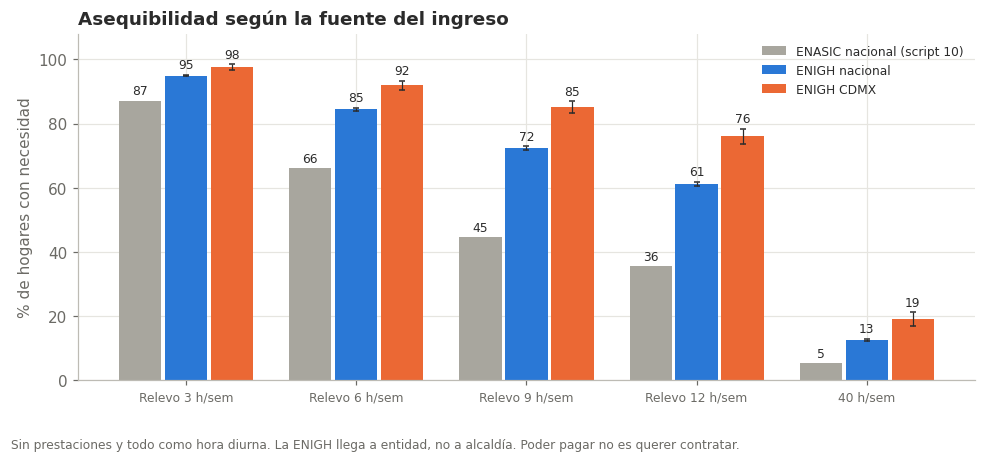

In [25]:
v = ver[ver.salario.str.startswith('Piso legal')].copy()
paqs = list(dict.fromkeys(v.sort_values('horas_semana').paquete))
fig, ax = plt.subplots(figsize=(9, 4.2)); x = np.arange(len(paqs)); w = .27
nac = v[v.dominio == 'Nacional'].set_index('paquete').loc[paqs]
cdmx = v[v.dominio == 'CDMX'].set_index('paquete').loc[paqs]
series = [('ENASIC nacional (script 10)', nac.enasic_nacional_script10, None, GRIS),
          ('ENIGH nacional', nac.pct, nac, AZUL), ('ENIGH CDMX', cdmx.pct, cdmx, NARANJA)]
for i, (et, val, dd, colr) in enumerate(series):
    err = None if dd is None else [dd.pct - dd.li90, dd.ls90 - dd.pct]
    b = ax.bar(x + (i - 1) * w, val, w * .92, color=colr, label=et, yerr=err, error_kw=dict(ecolor=TINTA, lw=.8, capsize=2))
    top = val.values if dd is None else dd.ls90.values
    for xi, vv, tt in zip(x + (i - 1) * w, val.values, top):
        ax.text(xi, tt + 1, f'{vv:.0f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x, [p.replace(' (control: script 04)', '').replace('Jornada completa ', '') for p in paqs], fontsize=8)
ax.set_ylabel('% de hogares con necesidad'); ax.set_ylim(0, 108); ax.legend(fontsize=8, loc='upper right')
ax.set_title('Asequibilidad según la fuente del ingreso')
nota(fig, 'Sin prestaciones y todo como hora diurna. La ENIGH llega a entidad, no a alcaldía. Poder pagar no es querer contratar.')
plt.show()